# Phase 2 — Technical validation of the final models (13)

Issue #72. Notebook 15 (#71) scored every final model once on the official FD001 test set. This notebook asks which of the differences it found are real, and states the outcome plainly, including ties and null results. Nothing is trained or scored again: every number comes from the saved per-engine test predictions.

**Terms**

- **Engine error:** each of the 100 test engines is scored once, at its last recorded cycle, against its true remaining useful life (RUL). A model's RMSE is over those 100 errors.
- **Seeds:** the networks ran at seeds 42–46, the ML baselines once. With several seeds, RMSE is the mean of the per-seed RMSEs, and an engine's absolute error is averaged over seeds (the #56 toolkit, `rul.evaluation.validation`).
- **Bootstrap 95% CI:** resample the 100 engines with replacement 10,000 times and take the middle 95% of the resampled RMSEs. A *paired* bootstrap resamples the same engines for both models, so it measures the difference engine by engine.
- **Wilcoxon signed-rank test:** a test on the per-engine absolute errors of two models. **Holm's correction** adjusts the p-values for running several tests as one family.
- **Value test (#83, fixed in advance):** a hybrid adds value over its best single branch only if (1) the paired bootstrap CI on the RMSE difference lies below zero, or (2) the Holm-corrected Wilcoxon p is below 0.05 with the hybrid's median error lower, or (3) its RMSE varies less across seeds with a mean that is no worse. Otherwise the result is null.

**Which comparisons, chosen before looking at the test.** Every pairing below is fixed by cross-validation on the training engines, not by the test scores:

- **Best sequence model against best ML model:** the sequence model with the lowest cross-validated selection RMSE (#58–#60) against the ML model with the lowest (#61), both trained with the cap of 125.
- **Each hybrid against its best single branch:** the branch #68 found best in cross-validation (`fd001_hybrid_value_test.json`). The three comparisons form one Holm family.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rul.evaluation.validation import bootstrap_ci, paired_bootstrap_diff, value_test

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
METRICS = ROOT / "results/metrics"
FIGURES = ROOT / "results/figures"
STAGES = {"late": (0, 50), "mid": (50, 100), "early": (100, np.inf)}  # true RUL, (low, high]

final = pd.read_csv(METRICS / "fd001_final_test_predictions.csv")
ml = pd.read_csv(METRICS / "fd001_ml_capped_test_predictions.csv").set_index("unit").sort_index()
units = ml.index.to_numpy()
y = ml["rul"].to_numpy(dtype=float)
assert (final.groupby("unit")["rul"].first().loc[units].to_numpy() == y).all(), "truth differs between files"

NETWORKS = {"lstm": "LSTM", "tcn": "Temporal CNN", "transformer": "Transformer",
            "hybrid_gated": "Hybrid A (gated)", "hybrid_two_stage": "Hybrid B (two-stage)"}
ML_NAMES = {"xgboost": "XGBoost", "random_forest": "Random Forest", "elastic_net": "Elastic Net"}
preds = {}  # (name, target) -> predictions shaped [seeds, engines]
for key, name in NETWORKS.items():
    for target in ("cap125", "uncapped"):
        wide = final.query("model == @key and target == @target").pivot(index="seed", columns="unit", values="prediction")
        preds[name, target] = wide[units].to_numpy()
for variant in ("engineered", "raw"):
    for key, name in ML_NAMES.items():
        for cap, target in (("125", "cap125"), ("none", "uncapped")):
            preds[f"{name} ({variant})", target] = ml[f"{variant}_{key}_cap{cap}"].to_numpy()[None, :]
print(f"{len(units)} test engines, true RUL {y.min():.0f} to {y.max():.0f}; "
      f"{len({n for n, _ in preds})} models, each capped and uncapped")

100 test engines, true RUL 7 to 145; 11 models, each capped and uncapped


## 1. Every model: seed spread and bootstrap CIs

`RMSE ± s.d.` is the mean and standard deviation over seeds (networks only). The CI is the bootstrap 95% interval over engines for the seed-averaged RMSE, so it shows how much the score depends on which 100 engines happen to be in the test set.

In [2]:
def seed_rmse(p):
    return np.sqrt(np.mean((p - y) ** 2, axis=1))


rows = []
for (name, target), p in preds.items():
    r = seed_rmse(p)
    ci = bootstrap_ci(y, p, "rmse")
    mae = bootstrap_ci(y, p, "mae")
    rows.append({"model": name, "target": target, "seeds": len(r),
                 "RMSE mean": r.mean(), "RMSE s.d.": r.std(ddof=1) if len(r) > 1 else np.nan,
                 "RMSE CI low": ci["low"], "RMSE CI high": ci["high"],
                 "MAE": mae["estimate"], "MAE CI low": mae["low"], "MAE CI high": mae["high"]})
models = pd.DataFrame(rows)
models.round(3).to_csv(METRICS / "fd001_validation_models.csv", index=False)


def show(target):
    t = models[models.target == target].sort_values("RMSE mean").set_index("model")
    return pd.DataFrame({
        "seeds": t["seeds"],
        "RMSE ± s.d.": [f"{m:.2f}" + (f" ± {s:.2f}" if pd.notna(s) else "") for m, s in zip(t["RMSE mean"], t["RMSE s.d."])],
        "RMSE 95% CI": [f"[{lo:.2f}, {hi:.2f}]" for lo, hi in zip(t["RMSE CI low"], t["RMSE CI high"])],
        "MAE 95% CI": [f"{m:.2f} [{lo:.2f}, {hi:.2f}]" for m, lo, hi in zip(t["MAE"], t["MAE CI low"], t["MAE CI high"])],
    })


print("Trained with the cap of 125")
display(show("cap125"))
print("Trained uncapped")
display(show("uncapped"))

Trained with the cap of 125


,seeds,RMSE ± s.d.,RMSE 95% CI,MAE 95% CI
model,,,,
Hybrid B (two-stage),5,15.18 ± 0.55,"[12.79, 17.47]","11.28 [9.38, 13.28]"
Hybrid A (gated),5,15.40 ± 0.46,"[13.15, 17.73]","11.89 [10.07, 13.79]"
Transformer,5,15.60 ± 0.35,"[13.38, 17.72]","11.91 [10.08, 13.82]"
XGBoost (engineered),1,15.71,"[13.24, 18.05]","11.59 [9.55, 13.73]"
Temporal CNN,5,15.83 ± 0.55,"[13.73, 17.88]","12.10 [10.35, 13.99]"
LSTM,5,15.95 ± 0.33,"[13.49, 18.36]","11.96 [10.01, 14.02]"
Random Forest (engineered),1,16.21,"[13.64, 18.64]","11.95 [9.86, 14.14]"
XGBoost (raw),1,17.58,"[14.70, 20.20]","12.78 [10.45, 15.18]"
Elastic Net (engineered),1,17.80,"[15.83, 19.62]","14.83 [12.90, 16.74]"


Trained uncapped


,seeds,RMSE ± s.d.,RMSE 95% CI,MAE 95% CI
model,,,,
XGBoost (raw),1,24.83,"[20.73, 28.79]","18.09 [14.84, 21.50]"
Hybrid B (two-stage),5,25.86 ± 1.07,"[20.93, 30.47]","17.71 [14.30, 21.36]"
Random Forest (raw),1,26.15,"[21.83, 30.36]","19.22 [15.87, 22.68]"
Hybrid A (gated),5,27.52 ± 1.10,"[22.14, 33.17]","19.75 [16.31, 23.60]"
Random Forest (engineered),1,27.55,"[21.07, 34.15]","17.67 [13.77, 22.07]"
Elastic Net (engineered),1,28.39,"[24.82, 32.08]","23.57 [20.56, 26.75]"
XGBoost (engineered),1,28.56,"[22.58, 34.46]","18.96 [14.95, 23.41]"
LSTM,5,28.97 ± 4.98,"[23.31, 34.41]","19.43 [15.69, 23.47]"
Elastic Net (raw),1,29.64,"[26.00, 33.15]","24.44 [21.19, 27.74]"


## 2. Paired tests and the value test

The pairings come from cross-validation. The next cell reads them from the saved tuning results and checks them, so a different test score could not have changed them.

Hybrid B's best branch in #68 was XGBoost on the engineered features. On the test set, that branch is the #61 XGBoost on engineered features. Its main settings match (depth 3, 200 trees, learning rate 0.1), but its feature pipeline is the Phase 1 one, and it ran with one seed. Criterion 3, lower seed variance, therefore can't be judged for Hybrid B, because the branch has no seed spread to compare against.

In [3]:
cv_seq = {NETWORKS[k]: json.loads((METRICS / f"fd001_cv_{k}.json").read_text())["summary"]["selection_rmse"]["mean"]
          for k in ("lstm", "tcn", "transformer")}
ml_cv = json.loads((METRICS / "fd001_ml_capped_cv.json").read_text())["chosen"]
cv_ml = {f"{ML_NAMES[c['model']]} ({c['variant']})": c["selection_rmse"]["mean"] for c in ml_cv if c["cap"] == "125"}
best_seq, best_ml = min(cv_seq, key=cv_seq.get), min(cv_ml, key=cv_ml.get)
branch_of = json.loads((METRICS / "fd001_hybrid_value_test.json").read_text())["best_branch"]
BRANCH_ON_TEST = {"sequence only (LSTM)": "LSTM", "XGBoost on features": "XGBoost (engineered)"}
hybrid_branch = {"Hybrid A (gated)": BRANCH_ON_TEST[branch_of["gated fusion (Hybrid A)"]],
                 "Hybrid B (two-stage)": BRANCH_ON_TEST[branch_of["two-stage (Hybrid B)"]]}

print("cross-validated selection RMSE, sequence models:", {k: round(v, 2) for k, v in cv_seq.items()})
print("cross-validated selection RMSE, ML (cap 125):   ", {k: round(v, 2) for k, v in cv_ml.items()})
print(f"best sequence model: {best_seq}; best ML model: {best_ml}")
print("best single branch (#68):", hybrid_branch)

COMPARISONS = {
    f"{h} vs {b}": (h, b) for h, b in hybrid_branch.items()
} | {f"{best_seq} vs {best_ml}": (best_seq, best_ml)}
pairs = {name: (preds[a, "cap125"], preds[b, "cap125"]) for name, (a, b) in COMPARISONS.items()}
verdicts = value_test(y, pairs)  # one Holm family across all three comparisons


def wins(a, b):
    return int((np.abs(a - y).mean(axis=0) < np.abs(b - y).mean(axis=0)).sum())


rows = []
for name, (a, b) in COMPARISONS.items():
    v, ev = verdicts[name], verdicts[name]["evidence"]
    d = ev["rmse_difference"]
    is_hybrid = name.startswith("Hybrid")
    rows.append({
        "comparison": name,
        "A RMSE": f"{ev['rmse_hybrid']['mean']:.2f}" + (f" ± {ev['rmse_hybrid']['std']:.2f}" if ev["rmse_hybrid"]["std"] else ""),
        "B RMSE": f"{ev['rmse_branch']['mean']:.2f}" + (f" ± {ev['rmse_branch']['std']:.2f}" if ev["rmse_branch"]["std"] else ""),
        "A - B [95% CI]": f"{d['difference']:+.2f} [{d['low']:+.2f}, {d['high']:+.2f}]",
        "Wilcoxon p": round(ev["wilcoxon"]["p"], 4), "Holm p": round(ev["wilcoxon"]["p_holm"], 4),
        "engines A better": wins(*pairs[name]),
        "(1) CI below 0": bool(v["criteria"]["bootstrap_ci_below_zero"]),
        "(2) Wilcoxon": bool(v["criteria"]["wilcoxon_holm"]),
        "(3) seed variance": bool(v["criteria"]["lower_seed_variance"]) if ev["rmse_branch"]["std"] else "n/a",
        "verdict": ("adds value" if v["adds_value"] else "null result") if is_hybrid else
                   ("A better" if d["high"] < 0 else "B better" if d["low"] > 0 else "no clear difference"),
    })
paired = pd.DataFrame(rows).set_index("comparison")
display(paired)

_ = (METRICS / "fd001_validation_value_test.json").write_text(json.dumps({
    "issue": 72, "data": "official FD001 test, last cycle per engine, cap 125 (#71)",
    "pairings_from": "cross-validation: fd001_cv_*.json, fd001_ml_capped_cv.json, fd001_hybrid_value_test.json",
    "holm_family": list(COMPARISONS), "comparisons": {k: list(v) for k, v in COMPARISONS.items()},
    "verdicts": verdicts,
}, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)) + "\n")

cross-validated selection RMSE, sequence models: {'LSTM': 15.78, 'Temporal CNN': 17.24, 'Transformer': 15.59}
cross-validated selection RMSE, ML (cap 125):    {'Random Forest (raw)': 19.0, 'XGBoost (raw)': 18.9, 'Elastic Net (raw)': 20.97, 'Random Forest (engineered)': 15.16, 'XGBoost (engineered)': 14.49, 'Elastic Net (engineered)': 18.94}
best sequence model: Transformer; best ML model: XGBoost (engineered)
best single branch (#68): {'Hybrid A (gated)': 'LSTM', 'Hybrid B (two-stage)': 'XGBoost (engineered)'}


,A RMSE,B RMSE,A - B [95% CI],Wilcoxon p,Holm p,engines A better,(1) CI below 0,(2) Wilcoxon,(3) seed variance,verdict
comparison,,,,,,,,,,
Hybrid A (gated) vs LSTM,15.40 ± 0.46,15.95 ± 0.33,"-0.54 [-3.35, +2.24]",0.5270,1.0,44,False,False,False,null result
Hybrid B (two-stage) vs XGBoost (engineered),15.18 ± 0.55,15.71,"-0.53 [-1.45, +0.38]",0.7439,1.0,47,False,False,n/a,null result
Transformer vs XGBoost (engineered),15.60 ± 0.35,15.71,"-0.11 [-2.42, +2.26]",0.6401,1.0,43,False,False,n/a,no clear difference


## 3. Where each model helps: stage-wise differences

The same paired bootstrap, restricted to the engines in one life stage (true RUL at the last cycle: late ≤ 50 < mid ≤ 100 < early). Each stage has about a third of the engines, so these intervals are wider. They are descriptive: they are not corrected for multiple tests and are not part of the value test.

In [4]:
stage_mask = {s: (y > lo) & (y <= hi) for s, (lo, hi) in STAGES.items()}
rows = []
for name, (a, b) in COMPARISONS.items():
    pa, pb = pairs[name]
    for stage, m in {"all": np.ones_like(y, bool), **stage_mask}.items():
        d = paired_bootstrap_diff(y[m], pa[:, m], pb[:, m])
        rows.append({"comparison": name, "stage": stage, "engines": int(m.sum()),
                     "A RMSE": np.sqrt(((pa[:, m] - y[m]) ** 2).mean(axis=1)).mean(),
                     "B RMSE": np.sqrt(((pb[:, m] - y[m]) ** 2).mean(axis=1)).mean(),
                     "difference": d["difference"], "CI low": d["low"], "CI high": d["high"],
                     "A mean error": (pa[:, m] - y[m]).mean(), "B mean error": (pb[:, m] - y[m]).mean()})
stagewise = pd.DataFrame(rows)
stagewise.round(3).to_csv(METRICS / "fd001_validation_paired.csv", index=False)
display(stagewise.set_index(["comparison", "stage"]).round(2))

rows = []
for (name, target), p in preds.items():
    if target != "cap125":
        continue
    for stage, m in stage_mask.items():
        ci = bootstrap_ci(y[m], p[:, m])
        rows.append({"model": name, "stage": stage, "RMSE": ci["estimate"], "low": ci["low"], "high": ci["high"]})
stage_models = pd.DataFrame(rows)
display(stage_models.pivot(index="model", columns="stage", values="RMSE")[list(STAGES)]
        .loc[models[models.target == "cap125"].sort_values("RMSE mean")["model"]].round(2))

engines  A RMSE  B RMSE  \
comparison                                   stage                            
Hybrid A (gated) vs LSTM                     all        100   15.40   15.95   
                                             late        33    5.08    5.50   
                                             mid         34   20.57   21.38   
                                             early       33   16.01   16.38   
Hybrid B (two-stage) vs XGBoost (engineered) all        100   15.18   15.71   
                                             late        33    6.16    6.27   
                                             mid         34   16.53   18.22   
                                             early       33   19.38   19.14   
Transformer vs XGBoost (engineered)          all        100   15.60   15.71   
                                             late        33    6.44    6.27   
                                             mid         34   21.06   18.22   
                                             early       33   15.42   19.14   

                                                    difference  CI low  \
comparison                                   stage                       
Hybrid A (gated) vs LSTM                     all         -0.54   -3.35   
                                             late        -0.41   -1.99   
                                             mid         -0.81   -6.34   
                                             early       -0.37   -4.02   
Hybrid B (two-stage) vs XGBoost (engineered) all         -0.53   -1.45   
                                             late        -0.10   -2.80   
                                             mid         -1.69   -3.25   
                                             early        0.24   -1.19   
Transformer vs XGBoost (engineered)          all         -0.11   -2.42   
                                             late         0.17   -1.38   
                                             mid          2.84   -1.66   
                                             early       -3.72   -6.61   

                                                    CI high  A mean error  \
comparison                                   stage                          
Hybrid A (gated) vs LSTM                     all       2.24          1.02   
                                             late      1.22          2.65   
                                             mid       4.40          7.42   
                                             early     3.64         -7.22   
Hybrid B (two-stage) vs XGBoost (engineered) all       0.38         -0.78   
                                             late      2.39          0.02   
                                             mid      -0.25          6.36   
                                             early     1.52         -8.94   
Transformer vs XGBoost (engineered)          all       2.26          2.85   
                                             late      2.05          1.89   
                                             mid       7.46         12.11   
                                             early    -0.75         -5.72   

                                                    B mean error  
comparison                                   stage                
Hybrid A (gated) vs LSTM                     all            2.65  
                                             late           2.09  
                                             mid           12.88  
                                             early         -7.32  
Hybrid B (two-stage) vs XGBoost (engineered) all           -0.06  
                                             late           1.36  
                                             mid            7.26  
                                             early         -9.02  
Transformer vs XGBoost (engineered)          all           -0.06  
                                             late           1.36  
                         

stage,late,mid,early
model,,,
Hybrid B (two-stage),6.16,16.53,19.38
Hybrid A (gated),5.08,20.57,16.01
Transformer,6.44,21.06,15.42
XGBoost (engineered),6.27,18.22,19.14
Temporal CNN,7.58,19.28,17.73
LSTM,5.50,21.38,16.38
Random Forest (engineered),7.39,18.14,20.05
XGBoost (raw),13.63,17.59,20.78
Elastic Net (engineered),17.51,15.93,19.80


## 4. Figure

Left: every model's test RMSE (cap 125) with its bootstrap 95% CI over engines. Right: the three paired differences, A minus B, overall and by stage; left of zero favours A.

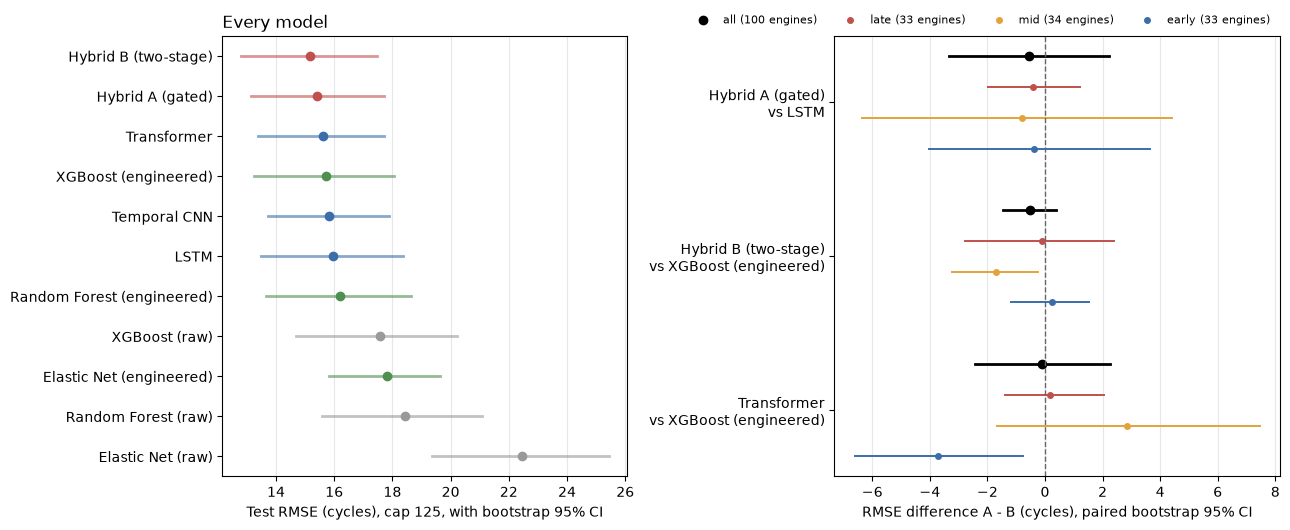

In [5]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1, 1.1]})
t = models[models.target == "cap125"].sort_values("RMSE mean", ascending=False)
colour = lambda n: "#c0504d" if n.startswith("Hybrid") else "#3b6ea8" if n in NETWORKS.values() else \
    "#4f8f4f" if "engineered" in n else "#9a9a9a"
for i, (_, r) in enumerate(t.iterrows()):
    ax.plot([r["RMSE CI low"], r["RMSE CI high"]], [i, i], color=colour(r["model"]), lw=2, alpha=0.6)
    ax.plot(r["RMSE mean"], i, "o", color=colour(r["model"]))
ax.set_yticks(range(len(t)), t["model"])
ax.set_xlabel("Test RMSE (cycles), cap 125, with bootstrap 95% CI")
ax.grid(axis="x", alpha=0.3)
ax.set_title("Every model", loc="left")

STAGE_COLOURS = {"all": "black", "late": "#c0504d", "mid": "#e3a33b", "early": "#3b6ea8"}
order = list(COMPARISONS)
offsets = dict(zip(STAGE_COLOURS, (0.3, 0.1, -0.1, -0.3)))
for i, name in enumerate(order[::-1]):
    for stage, off in offsets.items():
        r = stagewise[(stagewise.comparison == name) & (stagewise.stage == stage)].iloc[0]
        bx.plot([r["CI low"], r["CI high"]], [i + off] * 2, color=STAGE_COLOURS[stage], lw=2 if stage == "all" else 1.4)
        bx.plot(r["difference"], i + off, "o", color=STAGE_COLOURS[stage], ms=6 if stage == "all" else 4,
                label=f"{stage} ({int(r['engines'])} engines)" if i == 0 else None)
bx.axvline(0, color="#666", lw=1, ls="--")
bx.set_yticks(range(len(order)), [n.replace(" vs ", "\nvs ") for n in order[::-1]])
bx.set_xlabel("RMSE difference A - B (cycles), paired bootstrap 95% CI")
bx.legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=4)
bx.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "fd001_validation.png", dpi=150, bbox_inches="tight")
plt.show()